In [ ]:
! pip install bayesian-optimization scikit-optimize cma

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [bayesian-optimization]


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
#from bayes_opt import BayesianOptimization
import time
from skopt import gp_minimize
from skopt.space import Real
import cma

import pandas as pd


In [ ]:
def sphere_obj(x,d=None):
  x=np.asarray(x)
  if d is not None:
    if x.ndim==2:
      x=x[:,:d]   #many points at once
    else:
      x=x[:d]    # 1 pt
  return np.sum((x-1.)**2)



In [ ]:
def verify_optimum(D,d):  #first d-dimensions=1
  test_optimum=np.ones(D)
  test_optimum[d:]=999.9 #give noisy values for redund dim

  value=sphere_obj(test_optimum, d)
  print(f"VERIFICATION at {D=},{d=}: Value at theoretical optimum is {value}")

  assert np.isclose(value, 0.0), "Optimum Verification has failed!"

In [ ]:
class Logged:
  def __init__ (self, D, d, algo, seed):
    self.meta=dict(algorithm=algo, D=d, d=d, seed=seed)  #info for every record
    self.d, self.records, self.best=d, [], np.inf
    self.t0=time.perf_counter()

  def __call__ (self,x):
    t=time.perf_counter()
    y=float(sphere_obj(x,self.d))
    t_end=time.perf_counter()
    self.best=min(self.best,y)
    self.records.append({
        **self.meta,
        "eval_number":len(self.records)+1,
        "x":",".join(f"{a:.10g}"for a in x),
        "f_val":y,
        "best_so_far":self.best,
        "eval_duration":t_end-t,  #obj runtime
        "total_duration":t_end-self.t0   #runtime including all processes
    })
    return y

In [ ]:
BUDGET, LOWER_BD, UPPER_BD=100,-5.,5.

In [ ]:
 # Bayesian Opt:
def run_bo(D, d, seed):   #test for every combo of dim
  obj=Logged(D,d, "GP-BO", seed)
  gp_minimize(func=obj,
              dimensions=[ Real(LOWER_BD, UPPER_BD) for _ in range(D)],acq_func='EI',
              acq_optimizer='lbfgs',
              n_calls=BUDGET,  # to prevent high time complexity by capping calls to avoid cubic time lag
              n_initial_points=min(10,D*2),
              random_state=seed)
  return obj.records

#-------------------------------------------------------------------------
  #CMA-ES

def run_cma(D,d,seed):
  obj=Logged(D,d, "CMA-ES", seed)
  x0=np.random.default_rng(seed).uniform(LOWER_BD,UPPER_BD,D)  #D points that equally likely between interval
  es=cma.CMAEvolutionStrategy(
        x0, 0.3*(UPPER_BD-LOWER_BD),  #2nd arg: std of the first gen
        options={"seed": seed+1, "bounds":[LOWER_BD,UPPER_BD], "verbose":-9, "verb_log":0})

  while len(obj.records)<BUDGET:  #KEEP THE BUDGETS NUM SAME
    xs=es.ask()    #list of pts for curr gen
    fs=[]          #fn val
    for x in xs:
      if len(obj.records)>=BUDGET:
        break
      fs.append(obj(x))
    if len(fs)< len(xs):  #budget hitting mid-generation pts
      break
    es.tell(xs,fs)

  return obj.records


In [ ]:
if __name__=="__main__":
  configs=[(2,2),(5,5),(10,10),(20,20)]

  print("STEP 1: VERIFY OPTIMA")
  for D, d in configs:
    verify_optimum(D,d)

  print("STEP 2: RUNNING BENCHMARKS")

  rows=[]
  for D, d in configs:
    for seed in range(5):
      rows+=run_bo(D,d,seed)
      rows+=run_cma(D,d,seed)
  full_evals=pd.DataFrame(rows)       #all 100 sampled pts and their eval fn vals
  full_evals.to_csv("sphere_full_evals.csv",index=False)

  summary=(full_evals.groupby(["algorithm","D","d","seed"]).agg(
      best=("best_so_far","last"),
      n_evals=("eval_number","max"),
      total_time=("total_duration","max"))
      .reset_index())

  summary.to_csv("sphere_summary.csv", index=False)

  print(summary)

STEP 1: VERIFY OPTIMA
VERIFICATION at D=2,d=2: Value at theoretical optimum is 0.0
VERIFICATION at D=5,d=5: Value at theoretical optimum is 0.0
VERIFICATION at D=10,d=10: Value at theoretical optimum is 0.0
VERIFICATION at D=20,d=20: Value at theoretical optimum is 0.0
STEP 2: RUNNING BENCHMARKS
   algorithm   D   d  seed          best  n_evals  total_time
0     CMA-ES   2   2     0  5.505206e-03      100    0.025476
1     CMA-ES   2   2     1  2.564624e-03      100    0.022617
2     CMA-ES   2   2     2  5.182609e-02      100    0.032504
3     CMA-ES   2   2     3  3.336216e-04      100    0.034295
4     CMA-ES   2   2     4  2.011168e-03      100    0.029190
5     CMA-ES   5   5     0  4.939568e+00      100    0.022888
6     CMA-ES   5   5     1  1.929858e+00      100    0.032093
7     CMA-ES   5   5     2  2.249832e+00      100    0.024891
8     CMA-ES   5   5     3  5.584951e+00      100    0.037520
9     CMA-ES   5   5     4  4.035980e+00      100    0.035350
10    CMA-ES  10  10 

In [ ]:
#group by algo and (D,d) to get summary stats of each combo

summary=pd.read_csv('/content/sphere_summary.csv')

stats=(summary.groupby(["algorithm","D",'d'])['best']
       .agg(["count",'mean','median','std','min', 'max']).round(4)
       .reset_index())

print(stats)

# stats.pivot(index=['D','d'], columns='algorithm', values=['median','std'])




  algorithm   D   d  count     mean   median      std      min      max
0    CMA-ES   2   2      5   0.0124   0.0026   0.0221   0.0003   0.0518
1    CMA-ES   5   5      5   3.7480   4.0360   1.6146   1.9299   5.5850
2    CMA-ES  10  10      5  24.1243  21.6405   8.1049  15.9229  37.6002
3    CMA-ES  20  20      5  67.0970  69.6860  11.3405  52.1461  81.9878
4     GP-BO   2   2      5   0.0000   0.0000   0.0000   0.0000   0.0000
5     GP-BO   5   5      5   0.0000   0.0000   0.0000   0.0000   0.0001
6     GP-BO  10  10      5   0.0878   0.0976   0.0354   0.0518   0.1354
7     GP-BO  20  20      5  27.0911  18.4959  28.2241   1.5086  63.4205


median               std         
algorithm   CMA-ES    GP-BO   CMA-ES    GP-BO
D  d                                         
2  2        0.0026   0.0000   0.0221   0.0000
5  5        4.0360   0.0000   1.6146   0.0000
10 10      21.6405   0.0976   8.1049   0.0354
20 20      69.6860  18.4959  11.3405  28.2241

In [ ]:
full_evals=pd.read_csv("/content/sphere_full_evals.csv")

configs



,algorithm,D,d,seed,eval_number,x,f_val,best_so_far,eval_duration,total_duration
0,GP-BO,2,2,0,1,"0.9284461823,3.442657486",5.971696,5.971696,0.000077,0.021118
1,GP-BO,2,2,0,2,"3.579456176,3.472517388",12.766936,5.971696,0.000028,0.022169
2,GP-BO,2,2,0,3,"1.235636968,-1.156182927",4.704650,4.704650,0.000025,0.022690
3,GP-BO,2,2,0,4,"-2.024653935,-4.432870227",38.664610,4.704650,0.000022,0.023185
4,GP-BO,2,2,0,5,"1.953003255,5",16.908215,4.704650,0.000037,0.926994
...,...,...,...,...,...,...,...,...,...,...
3995,CMA-ES,20,20,4,96,"3.995931229,2.989208664,1.416393658,-3.4927202...",141.392602,60.389010,0.000011,0.034149
3996,CMA-ES,20,20,4,97,"-1.331092768,4.019038076,2.745832838,-1.417553...",114.384496,60.389010,0.000021,0.037160
3997,CMA-ES,20,20,4,98,"3.90959632,1.611920656,1.791580871,-0.29136911...",111.910657,60.389010,0.000014,0.037214
3998,CMA-ES,20,20,4,99,"3.864345557,3.409221205,2.237635697,1.99536306...",213.865200,60.389010,0.000015,0.037270


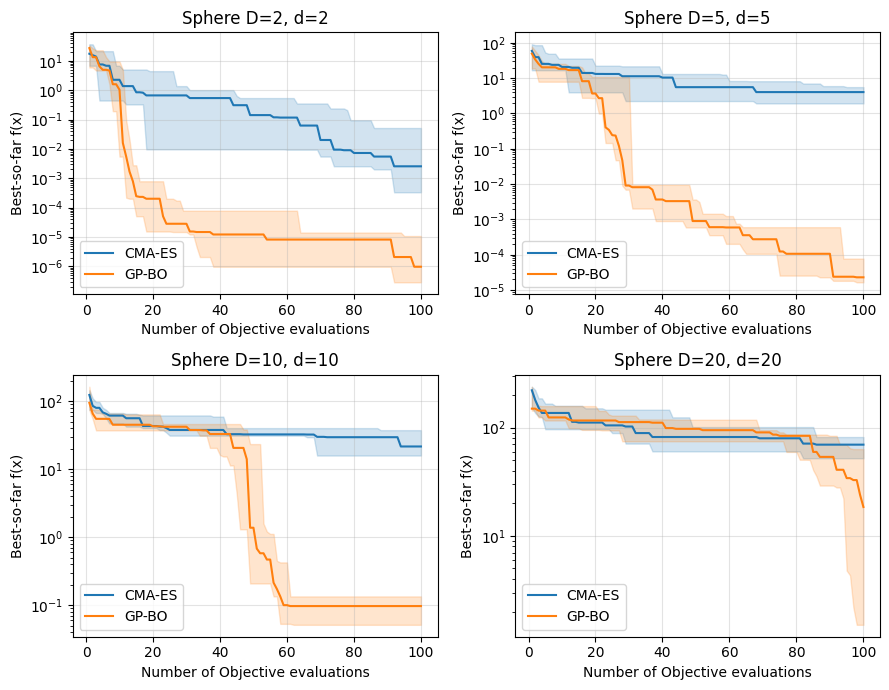

In [ ]:
configs = sorted(full_evals[["D", "d"]].drop_duplicates().itertuples(index=False, name=None))

colors = {"CMA-ES": "tab:blue", "GP-BO": "tab:orange"}

fig, axes = plt.subplots(2, 2, figsize=(9, 7), sharex=True)
axes = axes.ravel()   #2 by 2 array changed to list of 4 flat ones


for ax, (D, d) in zip(axes, configs):   #zip: pairs panels with corresp configs
    sub = full_evals[(full_evals["D"] == D) & (full_evals["d"] == d)]

    for algo, g in sub.groupby("algorithm"):
        curves = g.pivot(index="eval_number", columns="seed", values="best_so_far")  #long-> wide, values-> headers

        med = curves.median(axis=1)   #median curve of 100 evals out of 5 seeds
        ax.plot(curves.index, med, color=colors.get(algo), label=algo)

        ax.fill_between(curves.index, curves.min(axis=1), curves.max(axis=1),
                        color=colors.get(algo), alpha=0.2)   #shades area between best, worst seed per eval

    ax.set_yscale("log")  #log-scale to present all f_vals
    ax.set_title(f"Sphere D={D}, d={d}")
    ax.set_xlabel("Number of Objective evaluations")
    ax.tick_params(labelbottom=True)
    ax.grid(alpha=0.35)
    ax.set_ylabel("Best-so-far f(x)")
    ax.legend(loc='lower left')


plt.tight_layout()
plt.savefig("best_so_far_by_config.png", dpi=200)
plt.show()